# E-commerce Data Quality & Validation Pipeline
### Python + Statistics + Machine Learning, in one notebook

**What this project does.** Real-world data is dirty: duplicate customers, missing emails, wrong prices, orders that do
not add up. If that data goes into a dashboard or an ML model, the results are wrong. This notebook builds a pipeline that

1. **generates** realistic e-commerce data and *deliberately injects known defects* (so we have an answer key),
2. **validates** it with 13 config-driven rules,
3. **quarantines** bad rows and loads only trustworthy data into a SQLite warehouse,
4. answers **business questions with SQL** on the clean data,
5. uses **statistics** (descriptive stats, KS test, chi-square) to profile the data and check that cleaning did not distort it,
6. uses **machine learning** (Isolation Forest) to find anomalies, and compares it with classic statistical outlier methods,
7. **scores everything** with precision and recall against the answer key.

**How to read it.** Run the cells top to bottom. Cells that define code (sections 1, 3, 5, 8) are long, so you can skim
them first and come back. The result cells (tables and charts) are what matter for understanding.

**Requirements:** Python 3.10+, `pip install pandas numpy pyyaml scipy scikit-learn matplotlib`

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

SEED = 42                      # change it and every number below changes; same seed = same results
TABLE_NAMES = ["customers", "products", "orders", "order_items"]
for folder in ["data/raw", "warehouse", "config", "sql"]:
    Path(folder).mkdir(parents=True, exist_ok=True)

## 1. Synthetic data generator (with an answer key)

**Why synthetic?** Real dirty data comes with no answer key: you never know how many errors you missed. Here we first build
a *perfectly clean* dataset (customers, products, orders, order items), then inject 12 types of defects at known
rows and **log every one** in `defects`. Later we can measure how many the validator finds.

Details that keep the answer key honest: defects never overlap on the same row, order totals are recomputed after item
defects (so one defect does not secretly cause another), and future-dated signups only hit customers with no orders.

> Skim this cell. The important parts are `generate_clean`, `inject_defects`, and the `DEFECT_RATES` dictionary.

In [2]:
"""Synthetic e-commerce data generator with controlled, *recorded* defect injection.

Why synthetic? Real dirty data has no answer key. Here every defect we inject is
logged to ``_injected_defects.csv``, so the validator can later be scored with
precision and recall against ground truth.

Design rules that keep the answer key honest:
  * The clean data is fully consistent before any defect is injected.
  * Each defect touches a *disjoint* set of rows, so one row = one defect type.
  * Order totals are recomputed after item-level defects, so a bad item does not
    silently create a second (cascading) ``total_amount_mismatch``.
  * Future-dated signups are only injected on customers with no orders, so they
    do not cascade into ``order_before_signup``.
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

START = pd.Timestamp("2022-01-01")
SIGNUP_END = pd.Timestamp("2024-06-30")
END = pd.Timestamp("2025-06-30")
AS_OF = pd.Timestamp("2025-07-01")  # fixed "today" so runs are reproducible

FIRST_NAMES = ["Aarav", "Diya", "Kabir", "Meera", "Rohan", "Ananya", "Vikram", "Isha",
               "Arjun", "Sneha", "Liam", "Emma", "Noah", "Olivia", "Lukas", "Mia"]
LAST_NAMES = ["Sharma", "Iyer", "Reddy", "Patel", "Nair", "Singh", "Gupta", "Menon",
              "Smith", "Brown", "Muller", "Tan", "Wilson", "Khan", "Das", "Rao"]
COUNTRIES = ["India", "United States", "United Kingdom", "Germany", "Singapore", "Australia"]
COUNTRY_P = [0.55, 0.15, 0.10, 0.08, 0.07, 0.05]

# category -> (min, max) catalog price. Wide, *different* ranges per category are
# exactly why a global IQR outlier test is a poor fit here (see README).
CATEGORY_PRICE_RANGE = {
    "Electronics": (2000, 90000),
    "Books": (150, 1500),
    "Home & Kitchen": (400, 12000),
    "Fashion": (300, 6000),
    "Sports": (500, 15000),
    "Beauty": (100, 3000),
}
STATUSES = ["completed", "shipped", "pending", "cancelled", "returned"]
STATUS_P = [0.55, 0.15, 0.08, 0.12, 0.10]

# defect_type (== rule id in config/rules.yaml) -> fraction of its table affected
DEFECT_RATES = {
    "null_email": 0.02,
    "invalid_email": 0.02,
    "future_signup_date": 0.01,
    "duplicate_customer_id": 0.01,
    "non_positive_catalog_price": 0.02,
    "invalid_status": 0.015,
    "orphan_order_customer": 0.01,
    "order_before_signup": 0.01,
    "total_amount_mismatch": 0.015,
    "invalid_quantity": 0.01,
    "price_inconsistency": 0.015,
    "orphan_order_item": 0.01,
}


# --------------------------------------------------------------------------- #
# Clean data
# --------------------------------------------------------------------------- #
def generate_clean(n_customers: int, n_products: int, n_orders: int,
                   rng: np.random.Generator) -> dict[str, pd.DataFrame]:
    ids = np.arange(1, n_customers + 1)
    first = rng.choice(FIRST_NAMES, n_customers)
    last = rng.choice(LAST_NAMES, n_customers)
    signup_days = rng.integers(0, (SIGNUP_END - START).days + 1, n_customers)
    customers = pd.DataFrame({
        "customer_id": ids,
        "name": [f"{f} {l}" for f, l in zip(first, last)],
        "email": [f"{f}.{l}{i}@example.com".lower() for f, l, i in zip(first, last, ids)],
        "signup_date": START + pd.to_timedelta(signup_days, unit="D"),
        "country": rng.choice(COUNTRIES, n_customers, p=COUNTRY_P),
    })

    cats = rng.choice(list(CATEGORY_PRICE_RANGE), n_products)
    lo = np.array([CATEGORY_PRICE_RANGE[c][0] for c in cats])
    hi = np.array([CATEGORY_PRICE_RANGE[c][1] for c in cats])
    products = pd.DataFrame({
        "product_id": np.arange(1, n_products + 1),
        "name": [f"{c} Item {i}" for i, c in enumerate(cats, start=1)],
        "category": cats,
        "catalog_price": np.round(rng.uniform(lo, hi), 2),
    })

    # ~10% of customers never order: handy for safe defect injection later.
    active = rng.choice(ids, size=int(n_customers * 0.9), replace=False)
    cust_of_order = rng.choice(active, n_orders)
    signup = customers.set_index("customer_id").loc[cust_of_order, "signup_date"]
    span = (END - signup).dt.days.to_numpy()
    offset = (rng.random(n_orders) * span).astype(int)
    orders = pd.DataFrame({
        "order_id": np.arange(1, n_orders + 1),
        "customer_id": cust_of_order,
        "order_date": pd.to_datetime(signup.to_numpy()) + pd.to_timedelta(offset, unit="D"),
        "status": rng.choice(STATUSES, n_orders, p=STATUS_P),
        "total_amount": 0.0,  # filled in after item defects are injected
    })

    n_items = rng.integers(1, 5, n_orders)
    order_ids = np.repeat(orders["order_id"].to_numpy(), n_items)
    product_ids = rng.integers(1, n_products + 1, len(order_ids))
    catalog = products.set_index("product_id").loc[product_ids, "catalog_price"].to_numpy()
    items = pd.DataFrame({
        "item_id": np.arange(1, len(order_ids) + 1),
        "order_id": order_ids,
        "product_id": product_ids,
        "quantity": rng.integers(1, 5, len(order_ids)),
        # small legitimate discounts / markups around catalog price
        "unit_price": np.round(catalog * rng.uniform(0.92, 1.08, len(order_ids)), 2),
    })
    return {"customers": customers, "products": products, "orders": orders, "order_items": items}


# --------------------------------------------------------------------------- #
# Defect injection
# --------------------------------------------------------------------------- #
class _Injector:
    """Tracks used rows per table (so defects never overlap) and the answer key."""

    def __init__(self, rng: np.random.Generator):
        self.rng = rng
        self.used: dict[str, set[int]] = {}
        self.log: list[tuple[str, int, str]] = []

    def pick(self, table: str, pool, n: int) -> np.ndarray:
        used = self.used.setdefault(table, set())
        avail = np.setdiff1d(np.asarray(pool, dtype=int), np.array(sorted(used), dtype=int))
        chosen = np.sort(self.rng.choice(avail, size=min(n, len(avail)), replace=False))
        used.update(chosen.tolist())
        return chosen

    def record(self, table: str, rows, defect: str) -> None:
        self.log.extend((table, int(r), defect) for r in rows)


def _count(rates: dict, key: str, n_rows: int) -> int:
    return max(1, round(rates[key] * n_rows))


def inject_defects(t: dict[str, pd.DataFrame], rng: np.random.Generator,
                   rates: dict | None = None) -> tuple[dict[str, pd.DataFrame], pd.DataFrame]:
    rates = {**DEFECT_RATES, **(rates or {})}
    inj = _Injector(rng)
    cust, prod = t["customers"].copy(), t["products"].copy()
    orders, items = t["orders"].copy(), t["order_items"].copy()

    # ---- customers -------------------------------------------------------- #
    n = len(cust)
    idx = inj.pick("customers", cust.index, _count(rates, "null_email", n))
    cust.loc[idx, "email"] = None
    inj.record("customers", idx, "null_email")

    idx = inj.pick("customers", cust.index, _count(rates, "invalid_email", n))
    half = len(idx) // 2
    cust.loc[idx[:half], "email"] = cust.loc[idx[:half], "email"].str.replace("@", "", regex=False)
    cust.loc[idx[half:], "email"] = cust.loc[idx[half:], "email"].str.replace(".com", "", regex=False)
    inj.record("customers", idx, "invalid_email")

    no_orders = cust.index[~cust["customer_id"].isin(set(orders["customer_id"]))]
    idx = inj.pick("customers", no_orders, _count(rates, "future_signup_date", n))
    cust.loc[idx, "signup_date"] = (AS_OF + pd.to_timedelta(rng.integers(30, 400, len(idx)), unit="D")).to_numpy()
    inj.record("customers", idx, "future_signup_date")

    signup_lookup = cust.drop_duplicates("customer_id").set_index("customer_id")["signup_date"]

    src = inj.pick("customers", cust.index, _count(rates, "duplicate_customer_id", n))
    dups = cust.loc[src].copy()
    start = len(cust)
    cust = pd.concat([cust, dups], ignore_index=True)  # appended => original row indices unchanged
    inj.record("customers", np.arange(start, start + len(dups)), "duplicate_customer_id")

    # ---- products --------------------------------------------------------- #
    idx = inj.pick("products", prod.index, _count(rates, "non_positive_catalog_price", len(prod)))
    prod.loc[idx, "catalog_price"] = rng.choice([0.0, -5.0], len(idx))
    inj.record("products", idx, "non_positive_catalog_price")
    bad_products = set(prod.loc[idx, "product_id"])

    # ---- order_items ------------------------------------------------------ #
    n = len(items)
    idx = inj.pick("order_items", items.index, _count(rates, "invalid_quantity", n))
    items.loc[idx, "quantity"] = rng.choice([0, -1, -3, 500], len(idx))
    inj.record("order_items", idx, "invalid_quantity")

    pool = items.index[~items["product_id"].isin(bad_products)]  # need a valid catalog price to compare
    idx = inj.pick("order_items", pool, _count(rates, "price_inconsistency", n))
    factor = rng.choice([10.0, 0.1], len(idx))
    items.loc[idx, "unit_price"] = np.round(items.loc[idx, "unit_price"].to_numpy() * factor, 2)
    inj.record("order_items", idx, "price_inconsistency")

    idx = inj.pick("order_items", items.index, _count(rates, "orphan_order_item", n))
    items.loc[idx, "order_id"] = 800_000 + np.arange(len(idx))
    inj.record("order_items", idx, "orphan_order_item")

    # ---- order totals: computed AFTER item defects so they stay consistent --- #
    line = items["quantity"] * items["unit_price"]
    orders["total_amount"] = orders["order_id"].map(line.groupby(items["order_id"]).sum()).fillna(0).round(2)

    # ---- orders ----------------------------------------------------------- #
    n = len(orders)
    idx = inj.pick("orders", orders.index, _count(rates, "invalid_status", n))
    orders.loc[idx, "status"] = rng.choice(["COMPLETE", "delivered", "unknown", "Shipped "], len(idx))
    inj.record("orders", idx, "invalid_status")

    idx = inj.pick("orders", orders.index, _count(rates, "orphan_order_customer", n))
    orders.loc[idx, "customer_id"] = 900_000 + np.arange(len(idx))
    inj.record("orders", idx, "orphan_order_customer")

    idx = inj.pick("orders", orders.index, _count(rates, "order_before_signup", n))
    signup = orders.loc[idx, "customer_id"].map(signup_lookup)
    orders.loc[idx, "order_date"] = (signup - pd.to_timedelta(rng.integers(1, 120, len(idx)), unit="D")).to_numpy()
    inj.record("orders", idx, "order_before_signup")

    idx = inj.pick("orders", orders.index, _count(rates, "total_amount_mismatch", n))
    orders.loc[idx, "total_amount"] = (orders.loc[idx, "total_amount"] + np.round(rng.uniform(50, 500, len(idx)), 2)).round(2)
    inj.record("orders", idx, "total_amount_mismatch")

    # ---- serialise dates as ISO strings (what a CSV would really contain) --- #
    cust["signup_date"] = pd.to_datetime(cust["signup_date"]).dt.strftime("%Y-%m-%d")
    orders["order_date"] = pd.to_datetime(orders["order_date"]).dt.strftime("%Y-%m-%d")

    defects = pd.DataFrame(inj.log, columns=["table", "row_id", "defect_type"])
    return {"customers": cust, "products": prod, "orders": orders, "order_items": items}, defects


# --------------------------------------------------------------------------- #
# Public entry point
# --------------------------------------------------------------------------- #
def generate(out_dir: str | Path, seed: int = 42, n_customers: int = 1500, n_products: int = 200,
             n_orders: int = 5000, rates: dict | None = None) -> pd.DataFrame:
    """Write the four raw CSVs plus the defect answer key. Returns the answer key."""
    rng = np.random.default_rng(seed)
    clean = generate_clean(n_customers, n_products, n_orders, rng)
    dirty, defects = inject_defects(clean, rng, rates)
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    for name, df in dirty.items():
        df.to_csv(out / f"{name}.csv", index=False)
    defects.to_csv(out / "_injected_defects.csv", index=False)
    return defects

### Generate the data and look at it

In [3]:
defects = generate("data/raw", seed=SEED)
raw = {name: pd.read_csv(f"data/raw/{name}.csv") for name in TABLE_NAMES}

for name, df in raw.items():
    print(f"{name:12s} rows={len(df):>6,}  columns={list(df.columns)}")

display(raw["orders"].head())

customers    rows= 1,515  columns=['customer_id', 'name', 'email', 'signup_date', 'country']
products     rows=   200  columns=['product_id', 'name', 'category', 'catalog_price']
orders       rows= 5,000  columns=['order_id', 'customer_id', 'order_date', 'status', 'total_amount']
order_items  rows=12,482  columns=['item_id', 'order_id', 'product_id', 'quantity', 'unit_price']


,order_id,customer_id,order_date,status,total_amount
0,1,281,2023-05-24,completed,6522.09
1,2,1239,2024-11-22,pending,251083.64
2,3,1473,2025-05-15,cancelled,15924.58
3,4,430,2024-07-27,returned,47515.26
4,5,378,2025-05-27,completed,17578.69


,table,defect_type,injected
0,customers,duplicate_customer_id,15
1,customers,future_signup_date,15
2,customers,invalid_email,30
3,customers,null_email,30
4,order_items,invalid_quantity,125
5,order_items,orphan_order_item,125
6,order_items,price_inconsistency,187
7,orders,invalid_status,75
8,orders,order_before_signup,50
9,orders,orphan_order_customer,50


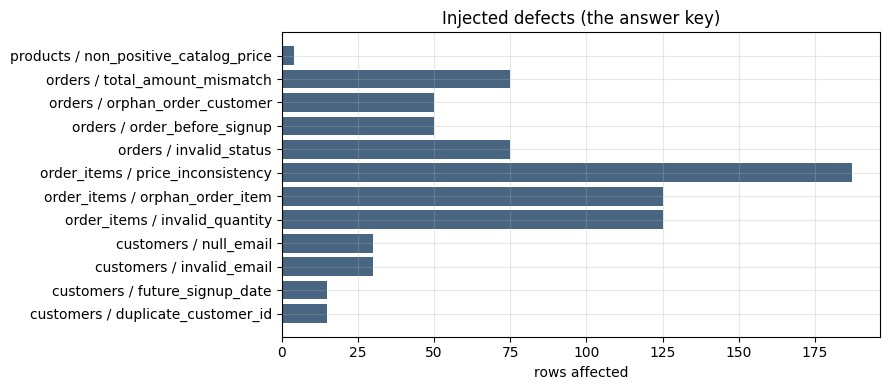

In [4]:
# The answer key: how many defects of each type did we inject, and into which table?
counts = defects.groupby(["table", "defect_type"]).size().rename("injected").reset_index()
display(counts)

labels = counts["table"] + " / " + counts["defect_type"]
plt.barh(labels, counts["injected"], color="#486581")
plt.title("Injected defects (the answer key)")
plt.xlabel("rows affected")
plt.tight_layout(); plt.show()

## 2. Exploratory look at the raw data

Before writing any rules, look at the data. Two things to notice:

* The **maximum** of `total_amount` and `unit_price` is hugely larger than the median, which is a red flag.
* **Price scales differ a lot by category** (Electronics up to ~90,000, Books ~150 to 1,500). This matters later:
  a "global outlier" test treats all prices as one population and will be wrong.

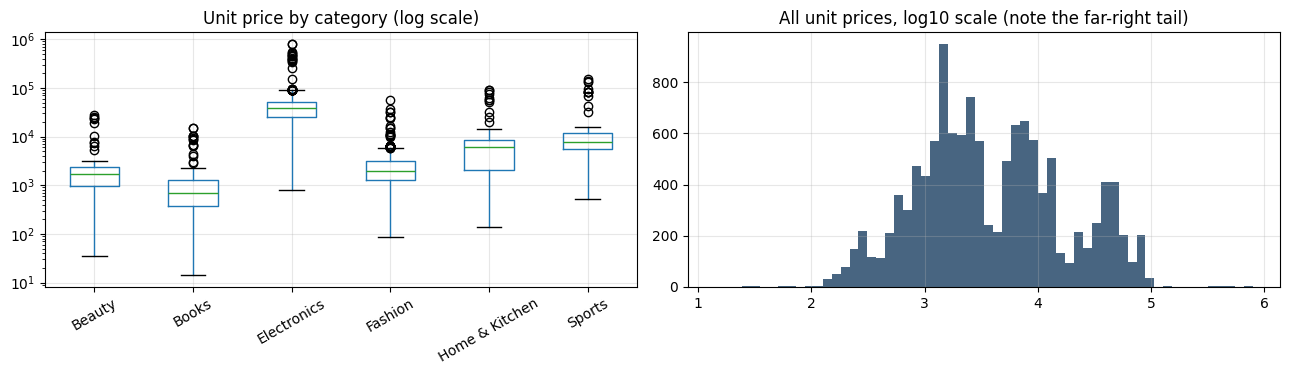

count        5000.00
mean        96245.32
std        676478.19
min       -172493.30
25%         10556.98
50%         32921.67
75%         91990.92
max      26179011.61
Name: total_amount, dtype: float64

In [5]:
items = raw["order_items"].merge(raw["products"][["product_id", "category"]], on="product_id")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
items.boxplot(column="unit_price", by="category", ax=ax[0], rot=30)
ax[0].set_yscale("log"); ax[0].set_title("Unit price by category (log scale)"); ax[0].set_xlabel("")
fig.suptitle("")
ax[1].hist(np.log10(items["unit_price"].clip(lower=1)), bins=60, color="#486581")
ax[1].set_title("All unit prices, log10 scale (note the far-right tail)")
plt.tight_layout(); plt.show()

display(raw["orders"]["total_amount"].describe().round(2))

## 3. Validation engine (rules)

A **rule** is one data-quality check, written in a small config (section 4). Each rule has a `type` (what to check) and a
`severity`:

* `error` → the bad rows are **quarantined** (kept out of the warehouse)
* `warning` → reported, but the rows are still loaded

Each check type is one small function registered with `@register("name")`. Adding a new type of check means writing one
function; no other code changes. The checks cover:

| Check type | Example |
|---|---|
| `not_null`, `unique`, `regex`, `range`, `allowed_values` | missing email, duplicate ID, bad email format, quantity ≤ 0, invalid status |
| `date_not_future`, `date_order` | signup in the future, order placed before the customer signed up |
| `foreign_key` | order points to a customer that does not exist |
| `price_consistency` | unit price differs >15% from the product's catalog price |
| `sum_match` | order total ≠ sum of its line items |

`evaluate_detection` at the bottom scores the rules against the answer key.

In [6]:
"""Config-driven validation engine.

Every rule in ``config/rules.yaml`` names a ``type``. Each type maps to one small
function registered below. A check returns ``(failed_row_labels, rows_checked)``.
Adding a new check type = write one function + decorate it. No other code changes.
"""
from __future__ import annotations

from pathlib import Path
from typing import Callable

import pandas as pd
import yaml

Tables = dict[str, pd.DataFrame]
CheckFn = Callable[[Tables, dict, pd.Timestamp], tuple[pd.Index, int]]

REGISTRY: dict[str, CheckFn] = {}
SEVERITIES = {"error", "warning"}


class ConfigError(ValueError):
    """Raised when rules.yaml is malformed."""


def register(name: str) -> Callable[[CheckFn], CheckFn]:
    def deco(fn: CheckFn) -> CheckFn:
        REGISTRY[name] = fn
        return fn
    return deco


def _failed(df: pd.DataFrame, mask) -> pd.Index:
    return df.index[pd.Series(mask, index=df.index).fillna(False).to_numpy(dtype=bool)]


# --------------------------------------------------------------------------- #
# Column-level checks
# --------------------------------------------------------------------------- #
@register("not_null")
def not_null(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    blank = s.isna() | (s.astype(str).str.strip() == "")
    return _failed(df, blank), len(df)


@register("unique")
def unique(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    # keep="first": only the *repeat* occurrences fail, the original row is fine
    return _failed(df, s.duplicated(keep="first") & s.notna()), int(s.notna().sum())


@register("regex")
def regex(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    present = s.notna()
    matches = s.astype(str).str.fullmatch(rule["pattern"])
    return _failed(df, present & ~matches), int(present.sum())


@register("range")
def value_range(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    num, present = pd.to_numeric(s, errors="coerce"), s.notna()
    bad = present & num.isna()  # non-numeric garbage
    if "min" in rule:
        bad = bad | (num < rule["min"])
    if "max" in rule:
        bad = bad | (num > rule["max"])
    return _failed(df, bad), int(present.sum())


@register("allowed_values")
def allowed_values(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    return _failed(df, s.notna() & ~s.isin(rule["values"])), int(s.notna().sum())


@register("date_not_future")
def date_not_future(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    parsed, present = pd.to_datetime(s, errors="coerce"), s.notna()
    return _failed(df, present & (parsed.isna() | (parsed > as_of))), int(present.sum())


# --------------------------------------------------------------------------- #
# Cross-table / business-logic checks
# --------------------------------------------------------------------------- #
@register("foreign_key")
def foreign_key(tables, rule, as_of):
    df, s = tables[rule["table"]], tables[rule["table"]][rule["column"]]
    parent = tables[rule["ref_table"]][rule["ref_column"]]
    return _failed(df, s.notna() & ~s.isin(parent)), int(s.notna().sum())


@register("date_order")
def date_order(tables, rule, as_of):
    """Child date must not be earlier than the parent's date (order >= signup)."""
    df = tables[rule["table"]]
    parents = tables[rule["ref_table"]].drop_duplicates(rule["ref_key"]).set_index(rule["ref_key"])
    parent_date = pd.to_datetime(df[rule["key"]].map(parents[rule["ref_column"]]), errors="coerce")
    child_date = pd.to_datetime(df[rule["column"]], errors="coerce")
    testable = child_date.notna() & parent_date.notna()  # orphans are caught by the FK rule
    return _failed(df, testable & (child_date < parent_date)), int(testable.sum())


@register("price_consistency")
def price_consistency(tables, rule, as_of):
    """Transaction price must be within +/- tolerance of the product's catalog price.

    Replaces a global IQR test: a 50,000 price is an "outlier" for Books but totally
    normal for Electronics, and IQR cannot know that. The catalog can.
    """
    df = tables[rule["table"]]
    ref = tables[rule["ref_table"]].drop_duplicates(rule["ref_key"]).set_index(rule["ref_key"])
    catalog = pd.to_numeric(df[rule["product_column"]].map(ref[rule["ref_price"]]), errors="coerce")
    price = pd.to_numeric(df[rule["column"]], errors="coerce")
    testable = catalog.gt(0) & price.notna()
    deviation = (price / catalog - 1).abs()
    return _failed(df, testable & (deviation > rule["tolerance"])), int(testable.sum())


@register("sum_match")
def sum_match(tables, rule, as_of):
    """Parent total must equal the sum of its child lines (qty * price)."""
    df, child = tables[rule["table"]], tables[rule["child_table"]]
    line = pd.to_numeric(child[rule["child_qty"]], errors="coerce") * pd.to_numeric(child[rule["child_price"]], errors="coerce")
    expected = df[rule["key"]].map(line.groupby(child[rule["child_key"]]).sum()).fillna(0)
    total = pd.to_numeric(df[rule["column"]], errors="coerce")
    testable = total.notna()
    return _failed(df, testable & ((total - expected).abs() > rule["tolerance"])), int(testable.sum())


# --------------------------------------------------------------------------- #
# Runner
# --------------------------------------------------------------------------- #
def load_config(path: str | Path) -> dict:
    cfg = yaml.safe_load(Path(path).read_text())
    if not isinstance(cfg, dict) or "rules" not in cfg:
        raise ConfigError("rules.yaml must contain a top-level 'rules' list")
    seen: set[str] = set()
    for rule in cfg["rules"]:
        for key in ("id", "type", "table", "severity", "description"):
            if key not in rule:
                raise ConfigError(f"rule {rule.get('id', rule)!r} is missing required key '{key}'")
        if rule["id"] in seen:
            raise ConfigError(f"duplicate rule id: {rule['id']}")
        seen.add(rule["id"])
        if rule["type"] not in REGISTRY:
            raise ConfigError(f"rule '{rule['id']}': unknown type '{rule['type']}' (known: {sorted(REGISTRY)})")
        if rule["severity"] not in SEVERITIES:
            raise ConfigError(f"rule '{rule['id']}': severity must be one of {sorted(SEVERITIES)}")
    return cfg


def run_validation(tables: Tables, cfg: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run every rule. Returns (rule_results, violations).

    rule_results: one row per rule (rows_checked, rows_failed, fail_rate ...)
    violations:   one row per failing record (rule_id, table_name, row_id, severity)
    """
    as_of = pd.Timestamp(cfg.get("as_of", pd.Timestamp.today().normalize()))
    results, violations = [], []
    for rule in cfg["rules"]:
        try:
            failed, checked = REGISTRY[rule["type"]](tables, rule, as_of)
        except KeyError as exc:
            raise ConfigError(f"rule '{rule['id']}' references missing table/column/param {exc}") from exc
        results.append({
            "rule_id": rule["id"], "description": rule["description"], "rule_type": rule["type"],
            "table_name": rule["table"], "severity": rule["severity"],
            "rows_checked": checked, "rows_failed": len(failed),
            "fail_rate_pct": round(100 * len(failed) / checked, 2) if checked else 0.0,
        })
        violations.extend(
            {"rule_id": rule["id"], "table_name": rule["table"], "row_id": int(r), "severity": rule["severity"]}
            for r in failed
        )
    cols = ["rule_id", "table_name", "row_id", "severity"]
    return pd.DataFrame(results), pd.DataFrame(violations, columns=cols)


def evaluate_detection(violations: pd.DataFrame, defects: pd.DataFrame, rule_ids: list[str]) -> pd.DataFrame:
    """Score the validator against the generator's answer key (precision / recall per rule)."""
    rows = []
    for rid in rule_ids:
        truth = set(zip(defects.loc[defects.defect_type == rid, "table"], defects.loc[defects.defect_type == rid, "row_id"]))
        v = violations[violations.rule_id == rid]
        flagged = set(zip(v["table_name"], v["row_id"]))
        tp = len(truth & flagged)
        rows.append({
            "rule_id": rid, "injected": len(truth), "flagged": len(flagged), "true_positives": tp,
            "recall_pct": round(100 * tp / len(truth), 1) if truth else None,
            "precision_pct": round(100 * tp / len(flagged), 1) if flagged else None,
        })
    return pd.DataFrame(rows)

## 4. The rules (configuration) and running them

The rules live in YAML so that someone who does not write Python can read and change them. The cell below writes the file
and runs every rule on the raw data.

In [7]:
from pathlib import Path

Path("config/rules.yaml").write_text(r"""
# Data-quality rules. Each rule is one entry; `type` selects the check in validators.py.
#   severity: error   -> offending rows are quarantined (kept out of the warehouse)
#   severity: warning -> reported, but rows are still loaded
as_of: "2025-07-01"   # "today" for future-date checks (fixed => reproducible runs)

rules:
  # ---------------- customers ----------------
  - id: null_email
    type: not_null
    table: customers
    column: email
    severity: warning
    description: Customer email is missing

  - id: invalid_email
    type: regex
    table: customers
    column: email
    pattern: '[^@\s]+@[^@\s]+\.[A-Za-z]{2,}'
    severity: warning
    description: Customer email is not a valid address format

  - id: duplicate_customer_id
    type: unique
    table: customers
    column: customer_id
    severity: error
    description: customer_id appears more than once

  - id: future_signup_date
    type: date_not_future
    table: customers
    column: signup_date
    severity: error
    description: Signup date is in the future (or unparseable)

  # ---------------- products ----------------
  - id: non_positive_catalog_price
    type: range
    table: products
    column: catalog_price
    min: 0.01
    severity: error
    description: Catalog price is zero or negative

  # ---------------- orders ----------------
  - id: invalid_status
    type: allowed_values
    table: orders
    column: status
    values: [completed, shipped, pending, cancelled, returned]
    severity: error
    description: Order status is not one of the allowed values

  - id: orphan_order_customer
    type: foreign_key
    table: orders
    column: customer_id
    ref_table: customers
    ref_column: customer_id
    severity: error
    description: Order references a customer that does not exist

  - id: order_before_signup
    type: date_order
    table: orders
    column: order_date
    key: customer_id
    ref_table: customers
    ref_key: customer_id
    ref_column: signup_date
    severity: error
    description: Order was placed before the customer signed up

  - id: future_order_date
    type: date_not_future
    table: orders
    column: order_date
    severity: error
    description: Order date is in the future (or unparseable)

  - id: total_amount_mismatch
    type: sum_match
    table: orders
    key: order_id
    column: total_amount
    child_table: order_items
    child_key: order_id
    child_qty: quantity
    child_price: unit_price
    tolerance: 0.01
    severity: error
    description: Order total does not equal the sum of its line items

  # ---------------- order_items ----------------
  - id: invalid_quantity
    type: range
    table: order_items
    column: quantity
    min: 1
    max: 100
    severity: error
    description: Quantity is outside 1-100

  - id: price_inconsistency
    type: price_consistency
    table: order_items
    column: unit_price
    product_column: product_id
    ref_table: products
    ref_key: product_id
    ref_price: catalog_price
    tolerance: 0.15
    severity: error
    description: Unit price deviates more than 15% from catalog price

  - id: orphan_order_item
    type: foreign_key
    table: order_items
    column: order_id
    ref_table: orders
    ref_column: order_id
    severity: error
    description: Order item references an order that does not exist
""")
print("wrote config/rules.yaml")

wrote config/rules.yaml


In [8]:
cfg = load_config("config/rules.yaml")
results, violations = run_validation(raw, cfg)

display(results[["rule_id", "table_name", "severity", "rows_checked", "rows_failed", "fail_rate_pct"]])
print(f"{len(violations):,} violating rows in total")

,rule_id,table_name,severity,rows_checked,rows_failed,fail_rate_pct
0,null_email,customers,warning,1515,30,1.98
1,invalid_email,customers,warning,1485,30,2.02
2,duplicate_customer_id,customers,error,1515,15,0.99
3,future_signup_date,customers,error,1515,15,0.99
4,non_positive_catalog_price,products,error,200,4,2.00
5,invalid_status,orders,error,5000,75,1.50
6,orphan_order_customer,orders,error,5000,50,1.00
7,order_before_signup,orders,error,4950,50,1.01
8,future_order_date,orders,error,5000,0,0.00
9,total_amount_mismatch,orders,error,5000,75,1.50


781 violating rows in total


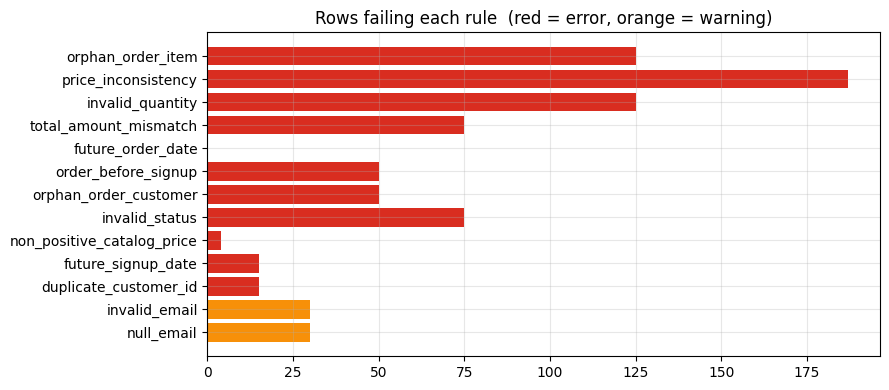

,order_id,customer_id,order_date,status,total_amount
33,34,154,2024-03-28,Shipped,98528.62
47,48,253,2023-09-04,delivered,10601.25
49,50,734,2025-05-20,delivered,429.37
109,110,420,2024-05-06,COMPLETE,63301.22
116,117,1292,2025-03-20,unknown,30228.97


In [9]:
colors = results["severity"].map({"error": "#d92d20", "warning": "#f79009"})
plt.barh(results["rule_id"], results["rows_failed"], color=colors)
plt.title("Rows failing each rule  (red = error, orange = warning)")
plt.tight_layout(); plt.show()

# Look at actual offending rows for one rule
bad_ids = violations.loc[violations["rule_id"] == "invalid_status", "row_id"].head(5)
display(raw["orders"].loc[bad_ids])

### How good is the validator? (precision and recall)

Because we know what we injected, we can measure the validator like an ML classifier:

* **Recall** = of the injected defects, what fraction did the rule find? (missed defects lower this)
* **Precision** = of the rows the rule flagged, what fraction were truly injected? (false alarms lower this)

Rules with no injected defects (`future_order_date`) show `None`.

In [10]:
evaluation = evaluate_detection(violations, defects, list(results["rule_id"]))
display(evaluation)

scored = evaluation.dropna(subset=["recall_pct"])
print(f"Mean recall {scored.recall_pct.mean():.1f}%  |  mean precision {scored.precision_pct.mean():.1f}%")

,rule_id,injected,flagged,true_positives,recall_pct,precision_pct
0,null_email,30,30,30,100.0,100.0
1,invalid_email,30,30,30,100.0,100.0
2,duplicate_customer_id,15,15,15,100.0,100.0
3,future_signup_date,15,15,15,100.0,100.0
4,non_positive_catalog_price,4,4,4,100.0,100.0
5,invalid_status,75,75,75,100.0,100.0
6,orphan_order_customer,50,50,50,100.0,100.0
7,order_before_signup,50,50,50,100.0,100.0
8,future_order_date,0,0,0,NaN,NaN
9,total_amount_mismatch,75,75,75,100.0,100.0


Mean recall 100.0%  |  mean precision 100.0%


## 5. Quarantine and the SQLite warehouse

Rules decide *which rows are bad*. The warehouse step decides *what to do about them*:

1. Rows that fail an `error` rule are held back.
2. **Cascade:** if a parent row is removed, its children go too (orders of a removed customer, items of a removed order).
3. If a line item is removed, its **order** is removed as well: the order total can no longer be trusted.

Good test of the logic: if we run the rules again on the warehouse, there should be **zero error failures**.
The cell also contains `read_sql_file` / `run_queries`, used in section 6.

In [11]:
"""SQLite warehouse: load only trustworthy rows, keep an audit trail of the rest.

Quarantine logic
  1. Rows that fail any ``severity: error`` rule are kept out of the warehouse.
  2. Referential cascade: children of removed parents are removed too
     (orders of a removed customer, items of a removed order/product).
  3. An order that lost any line item is removed as well. Its total can no
     longer be trusted, and keeping it would break ``total_amount_mismatch``
     on the next run.

Result: re-validating the warehouse gives zero error-severity failures.
"""
from __future__ import annotations

import sqlite3
from pathlib import Path

import pandas as pd


def quarantine(tables: dict[str, pd.DataFrame], violations: pd.DataFrame
               ) -> tuple[dict[str, pd.DataFrame], pd.DataFrame]:
    errors = violations[violations["severity"] == "error"]
    bad = errors.groupby("table_name")["row_id"].apply(set).to_dict()
    direct = {name: df.drop(index=list(bad.get(name, set()))) for name, df in tables.items()}

    customers, products = direct["customers"], direct["products"]
    orders = direct["orders"][direct["orders"]["customer_id"].isin(customers["customer_id"])]
    items = direct["order_items"]
    items = items[items["order_id"].isin(orders["order_id"]) & items["product_id"].isin(products["product_id"])]

    lost = tables["order_items"].loc[~tables["order_items"].index.isin(items.index)]
    orders = orders[~orders["order_id"].isin(set(lost["order_id"]))]
    items = items[items["order_id"].isin(orders["order_id"])]

    clean = {"customers": customers, "products": products, "orders": orders, "order_items": items}
    accounting = pd.DataFrame([{
        "table_name": name,
        "raw_rows": len(tables[name]),
        "failed_error_rules": len(bad.get(name, set())),
        "removed_by_cascade": len(direct[name]) - len(clean[name]),
        "loaded_rows": len(clean[name]),
    } for name in tables])
    return clean, accounting


def build_warehouse(db_path: str | Path, tables: dict[str, pd.DataFrame], violations: pd.DataFrame,
                    results: pd.DataFrame) -> tuple[dict[str, pd.DataFrame], pd.DataFrame]:
    clean, accounting = quarantine(tables, violations)
    path = Path(db_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with sqlite3.connect(path) as con:
        for name, df in clean.items():
            df.to_sql(name, con, if_exists="replace", index=False)
        violations.to_sql("dq_violations", con, if_exists="replace", index=False)
        results.to_sql("dq_rule_results", con, if_exists="replace", index=False)
        accounting.to_sql("dq_row_accounting", con, if_exists="replace", index=False)
        con.executescript("""
            CREATE INDEX IF NOT EXISTS ix_orders_customer  ON orders(customer_id);
            CREATE INDEX IF NOT EXISTS ix_items_order      ON order_items(order_id);
            CREATE INDEX IF NOT EXISTS ix_items_product    ON order_items(product_id);
            CREATE INDEX IF NOT EXISTS ix_viol_rule        ON dq_violations(rule_id);
        """)
    return clean, accounting


def read_sql_file(path: str | Path) -> dict[str, str]:
    """Parse a .sql file where each query is preceded by ``-- name: query_name``."""
    queries: dict[str, list[str]] = {}
    current = None
    for line in Path(path).read_text().splitlines():
        if line.strip().lower().startswith("-- name:"):
            current = line.split(":", 1)[1].strip()
            queries[current] = []
        elif current:
            queries[current].append(line)
    return {k: "\n".join(v).strip().rstrip(";") for k, v in queries.items()}


def run_queries(db_path: str | Path, queries: dict[str, str]) -> dict[str, pd.DataFrame]:
    with sqlite3.connect(db_path) as con:
        return {name: pd.read_sql_query(sql, con) for name, sql in queries.items()}

In [12]:
clean, accounting = build_warehouse("warehouse/ecommerce.db", raw, violations, results)
display(accounting)

# Re-validate what actually landed in the database
with sqlite3.connect("warehouse/ecommerce.db") as con:
    reloaded = {n: pd.read_sql_query(f"SELECT * FROM {n}", con) for n in TABLE_NAMES}
recheck, _ = run_validation(reloaded, cfg)
errors_left = int(recheck.loc[recheck["severity"] == "error", "rows_failed"].sum())
print("Error-severity failures left in the warehouse:", errors_left)
assert errors_left == 0

,table_name,raw_rows,failed_error_rules,removed_by_cascade,loaded_rows
0,customers,1515,30,0,1485
1,products,200,4,0,196
2,orders,5000,250,484,4266
3,order_items,12482,437,1721,10324


Error-severity failures left in the warehouse: 0


### Why it matters: what would dirty data have done to revenue?

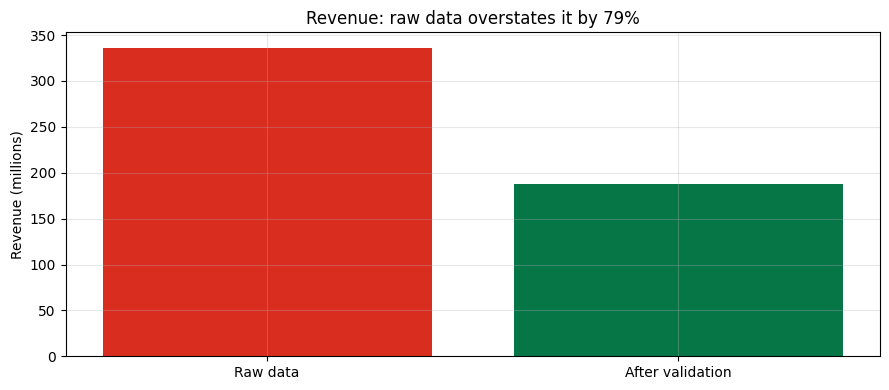

Raw: 336,170,204   Clean: 187,720,386   Overstated by 79.1%


In [13]:
REVENUE_STATUSES = ["completed", "shipped"]
rev_raw = raw["orders"].query("status in @REVENUE_STATUSES")["total_amount"].sum()
rev_clean = clean["orders"].query("status in @REVENUE_STATUSES")["total_amount"].sum()
overstated = 100 * (rev_raw - rev_clean) / rev_clean

plt.bar(["Raw data", "After validation"], [rev_raw / 1e6, rev_clean / 1e6], color=["#d92d20", "#067647"])
plt.ylabel("Revenue (millions)"); plt.title(f"Revenue: raw data overstates it by {overstated:.0f}%")
plt.tight_layout(); plt.show()
print(f"Raw: {rev_raw:,.0f}   Clean: {rev_clean:,.0f}   Overstated by {overstated:.1f}%")

## 6. Business questions in SQL (on the clean warehouse)

Now the data can be trusted, so we can answer business questions. The queries use joins, CTEs and window functions
(`RANK`, `LAG`). "Revenue" here means orders with status `completed` or `shipped`.

In [14]:
Path("sql/business_queries.sql").write_text(r"""
-- Business questions answered on the CLEAN warehouse.
-- Format: each query starts with "-- name: <query_name>". "Revenue" = completed + shipped orders.

-- name: monthly_revenue_last_12
SELECT strftime('%Y-%m', order_date)  AS month,
       COUNT(*)                        AS orders,
       ROUND(SUM(total_amount), 2)     AS revenue,
       ROUND(AVG(total_amount), 2)     AS avg_order_value
FROM orders
WHERE status IN ('completed', 'shipped')
GROUP BY month
ORDER BY month DESC
LIMIT 12;

-- name: revenue_growth_mom
WITH monthly AS (
    SELECT strftime('%Y-%m', order_date) AS month, SUM(total_amount) AS revenue
    FROM orders
    WHERE status IN ('completed', 'shipped')
    GROUP BY month
)
SELECT month,
       ROUND(revenue, 2) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct
FROM monthly
ORDER BY month DESC
LIMIT 12;

-- name: revenue_by_category
SELECT p.category,
       SUM(oi.quantity)                               AS units_sold,
       ROUND(SUM(oi.quantity * oi.unit_price), 2)     AS revenue
FROM order_items oi
JOIN orders   o ON o.order_id   = oi.order_id
JOIN products p ON p.product_id = oi.product_id
WHERE o.status IN ('completed', 'shipped')
GROUP BY p.category
ORDER BY revenue DESC;

-- name: top_10_customers_by_lifetime_value
SELECT RANK() OVER (ORDER BY SUM(o.total_amount) DESC) AS rank,
       c.customer_id,
       c.name,
       c.country,
       COUNT(*)                        AS orders,
       ROUND(SUM(o.total_amount), 2)   AS lifetime_value
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.status IN ('completed', 'shipped')
GROUP BY c.customer_id
ORDER BY rank
LIMIT 10;

-- name: repeat_customer_rate
WITH per_customer AS (
    SELECT customer_id, COUNT(*) AS n_orders FROM orders GROUP BY customer_id
)
SELECT COUNT(*)                                                      AS customers_with_orders,
       SUM(CASE WHEN n_orders >= 2 THEN 1 ELSE 0 END)                AS repeat_customers,
       ROUND(100.0 * SUM(CASE WHEN n_orders >= 2 THEN 1 ELSE 0 END)
             / COUNT(*), 1)                                          AS repeat_rate_pct
FROM per_customer;

-- name: cancel_and_return_rate_by_country
SELECT c.country,
       COUNT(*)                                                  AS orders,
       ROUND(100.0 * SUM(o.status = 'cancelled') / COUNT(*), 1)  AS cancel_pct,
       ROUND(100.0 * SUM(o.status = 'returned')  / COUNT(*), 1)  AS return_pct
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
GROUP BY c.country
ORDER BY orders DESC;

-- name: dq_failures_by_rule
SELECT rule_id, severity, rows_failed, fail_rate_pct
FROM dq_rule_results
WHERE rows_failed > 0
ORDER BY rows_failed DESC;
""")
print("wrote sql/business_queries.sql")

wrote sql/business_queries.sql


In [15]:
answers = run_queries("warehouse/ecommerce.db", read_sql_file("sql/business_queries.sql"))
for name, df in answers.items():
    print("\n##", name)
    display(df)


## monthly_revenue_last_12


,month,orders,revenue,avg_order_value
0,2025-06,106,7656165.82,72227.98
1,2025-05,139,8559790.06,61581.22
2,2025-04,123,7823992.41,63609.69
3,2025-03,115,7032486.55,61152.06
4,2025-02,122,8456763.52,69317.73
5,2025-01,126,8993802.17,71379.38
6,2024-12,106,6307880.15,59508.30
7,2024-11,117,7745417.45,66200.15
8,2024-10,121,7763840.01,64163.97
9,2024-09,126,9589804.61,76109.56



## revenue_growth_mom


,month,revenue,mom_growth_pct
0,2025-06,7656165.82,-10.6
1,2025-05,8559790.06,9.4
2,2025-04,7823992.41,11.3
3,2025-03,7032486.55,-16.8
4,2025-02,8456763.52,-6.0
5,2025-01,8993802.17,42.6
6,2024-12,6307880.15,-18.6
7,2024-11,7745417.45,-0.2
8,2024-10,7763840.01,-19.0
9,2024-09,9589804.61,-1.3



## revenue_by_category


,category,units_sold,revenue
0,Electronics,3232,1.326781e+08
1,Sports,2796,2.249850e+07
2,Home & Kitchen,3175,1.808120e+07
3,Fashion,3579,8.328491e+06
4,Beauty,2126,3.640516e+06
5,Books,3075,2.493607e+06


... (4 outputs left out)


## cancel_and_return_rate_by_country


,country,orders,cancel_pct,return_pct
0,India,2329,12.5,9.8
1,United States,684,12.4,11.1
2,United Kingdom,416,13.5,9.4
3,Germany,355,13.0,7.3
4,Singapore,271,12.5,12.2
5,Australia,211,11.4,11.8



## dq_failures_by_rule


,rule_id,severity,rows_failed,fail_rate_pct
0,price_inconsistency,error,187,1.53
1,invalid_quantity,error,125,1.00
2,orphan_order_item,error,125,1.00
3,invalid_status,error,75,1.50
4,total_amount_mismatch,error,75,1.50
5,orphan_order_customer,error,50,1.00
6,order_before_signup,error,50,1.01
7,null_email,warning,30,1.98
8,invalid_email,warning,30,2.02
9,duplicate_customer_id,error,15,0.99


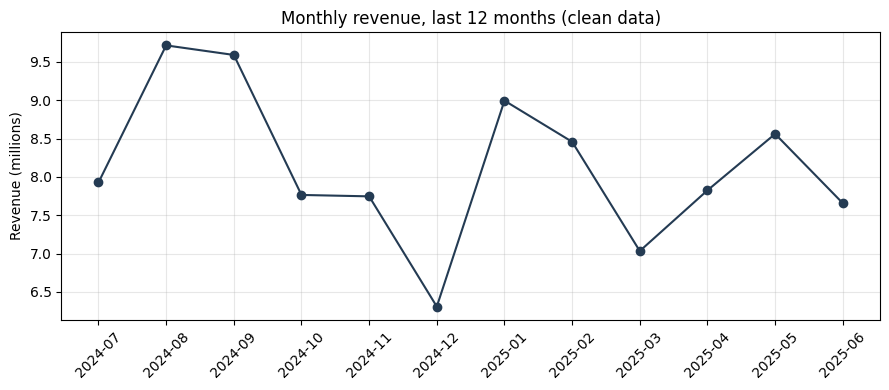

In [16]:
monthly = answers["monthly_revenue_last_12"].sort_values("month")
plt.plot(monthly["month"], monthly["revenue"] / 1e6, marker="o", color="#243b53")
plt.xticks(rotation=45); plt.ylabel("Revenue (millions)"); plt.title("Monthly revenue, last 12 months (clean data)")
plt.tight_layout(); plt.show()

## 7. Statistics

### 7a. Column profile of the raw data
Mean, standard deviation, min, median, max and **skewness** per numeric column. A huge skew (a long right tail) or a
max far above the median is an early statistical warning sign.

### 7b. Did cleaning change the distributions?
We removed rows. Did we also change the *shape* of the data? Two classic tests compare raw vs clean:

* **Kolmogorov-Smirnov (KS) test** for numeric columns. The KS statistic is the largest gap between the two cumulative
  distributions: 0 means identical, 1 means completely different.
* **Chi-square test** for categorical columns, with **Cramér's V** as the effect size.

With thousands of rows almost any tiny difference is "statistically significant" (small p-value), so read the **effect
size**, not just the p-value. That is a good point to make in an interview.

**Code for sections 7 and 8.** This one cell holds the statistics and ML functions (`profile_columns`, `drift_tests`, `item_features`, `isolation_forest`, `compare_outlier_methods`, `ml_recall_by_defect`). Skim it now; the results come right after.

In [17]:
"""Statistics + machine learning layer.

Rules catch defects you can *name*. Statistics and ML help with the rest:

  * profile_columns       - descriptive statistics (mean, std, skew, null %) per numeric column
  * drift_tests           - KS test / chi-square: did cleaning change the distributions?
  * isolation_forest      - unsupervised anomaly detection on order-item features
  * compare_outlier_methods - Tukey IQR vs MAD z-score vs Isolation Forest vs catalog rule,
                              all scored against the injected-defect answer key
  * ml_recall_by_defect   - which defect types can ML see, and which need rules?
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import IsolationForest

Tables = dict[str, pd.DataFrame]


# --------------------------------------------------------------------------- #
# Descriptive statistics
# --------------------------------------------------------------------------- #
def profile_columns(tables: Tables) -> pd.DataFrame:
    rows = []
    for name, df in tables.items():
        for col in df.columns:
            s = df[col]
            row = {"table": name, "column": col, "null_pct": round(100 * s.isna().mean(), 2), "distinct": int(s.nunique())}
            if pd.api.types.is_numeric_dtype(s) and not col.endswith("_id"):
                row.update(mean=round(s.mean(), 2), std=round(s.std(), 2), min=s.min(),
                           median=s.median(), max=s.max(), skew=round(float(stats.skew(s.dropna())), 2))
            rows.append(row)
    return pd.DataFrame(rows).dropna(subset=["mean"]).reset_index(drop=True)


def drift_tests(raw: Tables, clean: Tables) -> pd.DataFrame:
    """Two-sample tests: raw vs. cleaned distributions.

    KS statistic = largest gap between the two empirical CDFs (0 = identical, 1 = disjoint).
    Cramer's V = effect size of the chi-square test for categorical columns.
    With thousands of rows almost everything is 'significant', so read the *effect size*.
    """
    rows = []
    for table, col in [("order_items", "unit_price"), ("order_items", "quantity"), ("orders", "total_amount")]:
        a = pd.to_numeric(raw[table][col], errors="coerce").dropna()
        b = pd.to_numeric(clean[table][col], errors="coerce").dropna()
        ks = stats.ks_2samp(a, b)
        rows.append({"table": table, "column": col, "test": "Kolmogorov-Smirnov",
                     "effect_size": round(float(ks.statistic), 4), "p_value": float(ks.pvalue)})
    for table, col in [("orders", "status"), ("customers", "country")]:
        counts = pd.concat([raw[table][col].value_counts().rename("raw"), clean[table][col].value_counts().rename("clean")],
                           axis=1).fillna(0)
        chi2, p, _, _ = stats.chi2_contingency(counts.to_numpy())
        v = np.sqrt(chi2 / counts.to_numpy().sum())  # Cramer's V for a 2-column table
        rows.append({"table": table, "column": col, "test": "Chi-square",
                     "effect_size": round(float(v), 4), "p_value": float(p)})
    out = pd.DataFrame(rows)
    out["p_value"] = out["p_value"].map(lambda p: f"{p:.2e}")
    return out


# --------------------------------------------------------------------------- #
# Features + Isolation Forest
# --------------------------------------------------------------------------- #
def item_features(tables: Tables, engineered: bool = True) -> pd.DataFrame:
    """Numeric features per order line.

    engineered=False -> only raw columns (price, quantity, catalog price)
    engineered=True  -> adds log(price / catalog price): the domain-knowledge feature
    """
    items = tables["order_items"]
    prod = tables["products"].drop_duplicates("product_id").set_index("product_id")
    catalog = pd.to_numeric(items["product_id"].map(prod["catalog_price"]), errors="coerce")
    price = pd.to_numeric(items["unit_price"], errors="coerce")
    qty = pd.to_numeric(items["quantity"], errors="coerce")
    X = pd.DataFrame({"log_price": np.log1p(price.clip(lower=0)), "quantity": qty,
                      "log_catalog": np.log1p(catalog.clip(lower=0))}, index=items.index)
    if engineered:
        ratio = (price / catalog).where(catalog > 0).clip(lower=1e-3)
        X["log_price_ratio"] = np.log(ratio)
    return X.fillna(X.median())


def isolation_forest(X: pd.DataFrame, contamination: float = 0.03, seed: int = 42) -> tuple[pd.Series, set]:
    """Returns (anomaly_score, flagged_row_labels). Higher score = more anomalous."""
    model = IsolationForest(n_estimators=300, contamination=contamination, random_state=seed)
    model.fit(X)
    score = pd.Series(-model.score_samples(X), index=X.index, name="anomaly_score")
    flagged = set(X.index[model.predict(X) == -1])
    return score, flagged


# --------------------------------------------------------------------------- #
# Method comparison against ground truth
# --------------------------------------------------------------------------- #
def _score(name: str, flagged: set, truth: set) -> dict:
    tp = len(flagged & truth)
    precision = tp / len(flagged) if flagged else 0.0
    recall = tp / len(truth) if truth else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"method": name, "flagged": len(flagged), "true_positives": tp,
            "precision_pct": round(100 * precision, 1), "recall_pct": round(100 * recall, 1), "f1_pct": round(100 * f1, 1)}


def compare_outlier_methods(tables: Tables, violations: pd.DataFrame, defects: pd.DataFrame, seed: int = 42) -> pd.DataFrame:
    """How well does each method find the injected *wrong-price* lines?"""
    items = tables["order_items"]
    truth = set(defects.loc[(defects.table == "order_items") & (defects.defect_type == "price_inconsistency"), "row_id"])
    price = pd.to_numeric(items["unit_price"], errors="coerce")

    q1, q3 = price.quantile([0.25, 0.75])
    iqr = q3 - q1
    tukey = set(items.index[(price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)])

    log_p = np.log(price.clip(lower=0.01))
    mad = (log_p - log_p.median()).abs().median()
    modified_z = 0.6745 * (log_p - log_p.median()) / mad  # Iglewicz-Hoaglin modified z-score
    mad_flags = set(items.index[modified_z.abs() > 3.5])

    _, if_raw = isolation_forest(item_features(tables, engineered=False), seed=seed)
    _, if_eng = isolation_forest(item_features(tables, engineered=True), seed=seed)
    rule = set(violations.loc[violations.rule_id == "price_inconsistency", "row_id"])

    return pd.DataFrame([
        _score("Global IQR (Tukey, 1.5x)", tukey, truth),
        _score("Global modified z-score (MAD, log price)", mad_flags, truth),
        _score("Isolation Forest - raw features", if_raw, truth),
        _score("Isolation Forest - + price/catalog ratio", if_eng, truth),
        _score("Catalog-consistency rule (+/-15%)", rule, truth),
    ])


def ml_recall_by_defect(tables: Tables, defects: pd.DataFrame, seed: int = 42) -> pd.DataFrame:
    """Which injected order-item defects does Isolation Forest catch on its own?"""
    _, flagged = isolation_forest(item_features(tables, engineered=True), seed=seed)
    rows = []
    for dtype, grp in defects[defects.table == "order_items"].groupby("defect_type"):
        truth = set(grp["row_id"])
        rows.append({"defect_type": dtype, "injected": len(truth), "caught_by_ml": len(truth & flagged),
                     "recall_pct": round(100 * len(truth & flagged) / len(truth), 1)})
    return pd.DataFrame(rows)

In [18]:
profile = profile_columns(raw)
display(profile)

,table,column,null_pct,distinct,mean,std,min,median,max,skew
0,products,catalog_price,0.0,198,10007.02,16450.89,-5.00,2904.415,86394.32,2.57
1,orders,total_amount,0.0,4980,96245.32,676478.19,-172493.30,32921.670,26179011.61,32.12
2,order_items,quantity,0.0,8,3.46,22.28,-3.00,2.000,500.00,22.19
3,order_items,unit_price,0.0,12394,11352.84,24210.31,14.04,2999.940,801793.00,11.99


,table,column,test,effect_size,p_value
0,order_items,unit_price,Kolmogorov-Smirnov,0.0076,8.98e-01
1,order_items,quantity,Kolmogorov-Smirnov,0.0080,8.58e-01
2,orders,total_amount,Kolmogorov-Smirnov,0.0165,5.52e-01
3,orders,status,Chi-square,0.0837,4.93e-11
4,customers,country,Chi-square,0.0047,1.00e+00


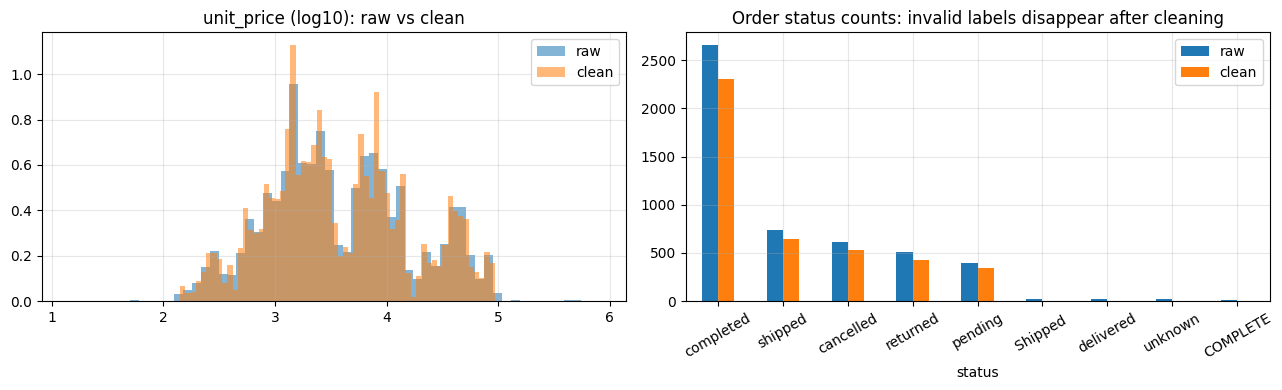

In [19]:
drift = drift_tests(raw, clean)
display(drift)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for label, tbl in [("raw", raw), ("clean", clean)]:
    ax[0].hist(np.log10(tbl["order_items"]["unit_price"].clip(lower=1)), bins=60, alpha=0.55, density=True, label=label)
ax[0].set_title("unit_price (log10): raw vs clean"); ax[0].legend()
status = pd.concat([raw["orders"]["status"].value_counts().rename("raw"),
                    clean["orders"]["status"].value_counts().rename("clean")], axis=1).fillna(0)
status.plot.bar(ax=ax[1], rot=30); ax[1].set_title("Order status counts: invalid labels disappear after cleaning")
plt.tight_layout(); plt.show()

## 8. Machine learning: anomaly detection with Isolation Forest

Rules only catch defects someone thought to write a rule for. **Anomaly detection** looks for rows that simply *look
unusual*. We use **Isolation Forest** (unsupervised): it builds random trees that try to isolate each row; anomalies are
isolated with fewer splits, so they get a higher anomaly score.

**The question we test:** which method best finds the injected *wrong-price* order lines?

* Global **IQR** (Tukey): flag prices beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR
* Global **modified z-score** (MAD) on log price
* **Isolation Forest** on raw features (log price, quantity, log catalog price)
* **Isolation Forest + engineered feature** `log(price / catalog price)`
* The **catalog-consistency rule** from section 3

Everything is scored with precision, recall and F1 against the answer key. The functions are defined in the cell at the start of section 7.

,method,flagged,true_positives,precision_pct,recall_pct,f1_pct
0,"Global IQR (Tukey, 1.5x)",1873,49,2.6,26.2,4.8
1,"Global modified z-score (MAD, log price)",3,3,100.0,1.6,3.2
2,Isolation Forest - raw features,375,9,2.4,4.8,3.2
3,Isolation Forest - + price/catalog ratio,375,181,48.3,96.8,64.4
4,Catalog-consistency rule (+/-15%),187,187,100.0,100.0,100.0


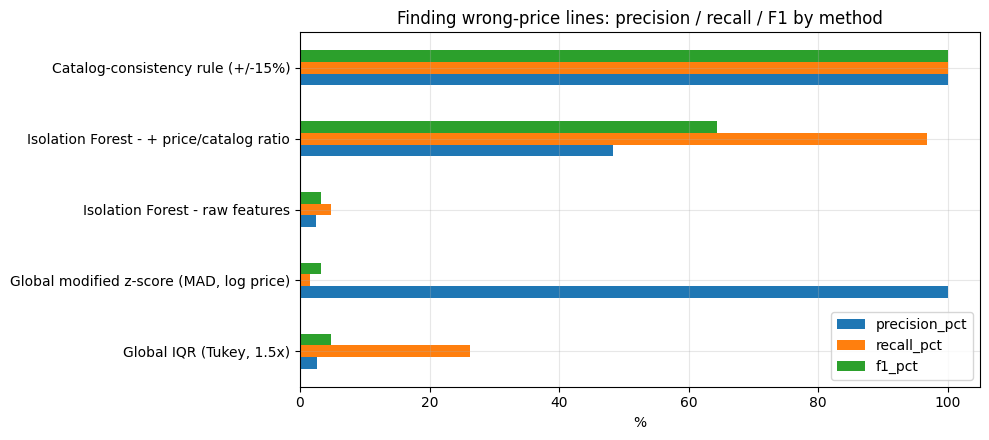

In [20]:
comparison = compare_outlier_methods(raw, violations, defects, seed=SEED)
display(comparison)

ax = comparison.set_index("method")[["precision_pct", "recall_pct", "f1_pct"]].plot.barh(figsize=(10, 4.5))
ax.set_title("Finding wrong-price lines: precision / recall / F1 by method")
ax.set_xlabel("%"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

**Reading the table.**

* **Global IQR** flags far too many rows (low precision): it cannot know that 50,000 is normal for Electronics but wrong for
  a Book.
* **Modified z-score** is very strict: it flags only 3 rows (perfect precision, almost no recall).
* **Isolation Forest on raw features** does poorly, because a wrong price looks plausible *by itself*.
* **Isolation Forest + the price/catalog ratio** reaches high recall. **Feature engineering with domain knowledge**
  made the difference, not a fancier algorithm.
* The **rule** is exact here, because the catalog gives us the ground truth for the price.

### What can ML see on its own?

,defect_type,injected,caught_by_ml,recall_pct
0,invalid_quantity,125,9,7.2
1,orphan_order_item,125,2,1.6
2,price_inconsistency,187,181,96.8


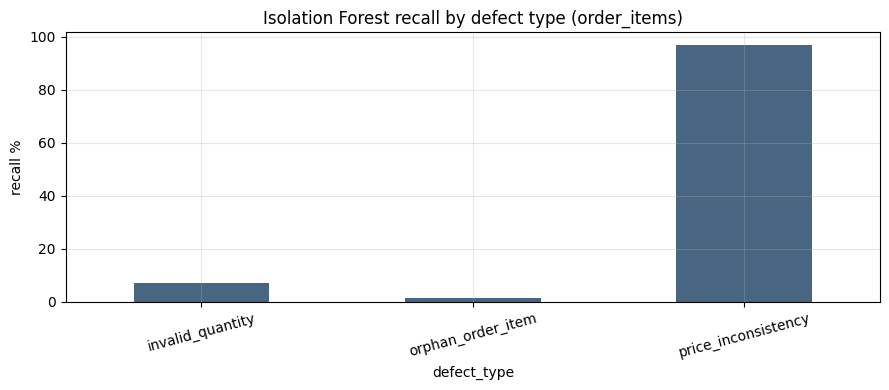

In [21]:
ml_recall = ml_recall_by_defect(raw, defects, seed=SEED)
display(ml_recall)

ml_recall.set_index("defect_type")["recall_pct"].plot.bar(color="#486581", rot=15)
plt.ylabel("recall %"); plt.title("Isolation Forest recall by defect type (order_items)")
plt.tight_layout(); plt.show()

Isolation Forest finds **value anomalies** (wrong prices) but is almost blind to **structural defects** such as an
`order_id` that points to nothing: the row's numbers look completely normal. That is why the final design uses rules as the
gate and ML as a second safety net.

### Look inside the model: anomaly scores

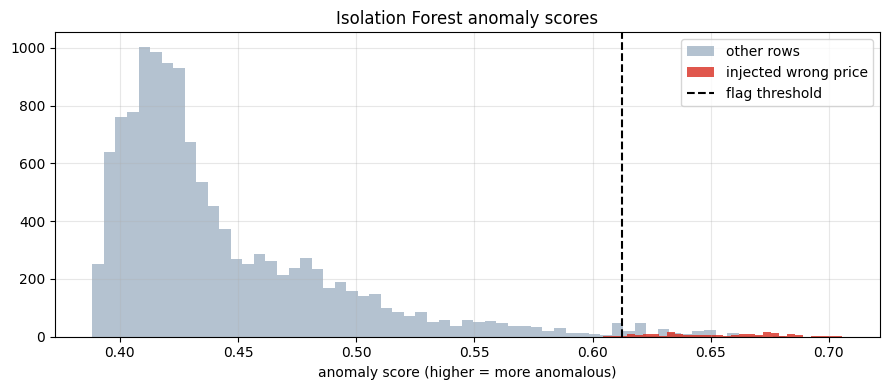

In [22]:
X = item_features(raw, engineered=True)
score, flagged = isolation_forest(X, contamination=0.03, seed=SEED)
truth = set(defects.loc[(defects["table"] == "order_items") & (defects["defect_type"] == "price_inconsistency"), "row_id"])
is_wrong_price = score.index.isin(truth)

plt.hist(score[~is_wrong_price], bins=60, alpha=0.6, label="other rows", color="#829ab1")
plt.hist(score[is_wrong_price], bins=30, alpha=0.8, label="injected wrong price", color="#d92d20")
plt.axvline(score[list(flagged)].min(), color="black", ls="--", label="flag threshold")
plt.xlabel("anomaly score (higher = more anomalous)"); plt.legend(); plt.title("Isolation Forest anomaly scores")
plt.tight_layout(); plt.show()

### Tuning the one assumption: `contamination`
Isolation Forest needs a guess of what fraction of rows are anomalies. We used 3%. What if the guess is wrong? Sweep it and
watch the precision/recall trade-off (higher contamination flags more rows: recall goes up, precision goes down).

,contamination,flagged,precision_pct,recall_pct
0,0.005,63,95.2,32.1
1,0.010,124,77.4,51.3
2,0.020,249,57.8,77.0
3,0.030,375,48.3,96.8
4,0.050,625,29.9,100.0
5,0.080,999,18.7,100.0
6,0.120,1498,12.5,100.0


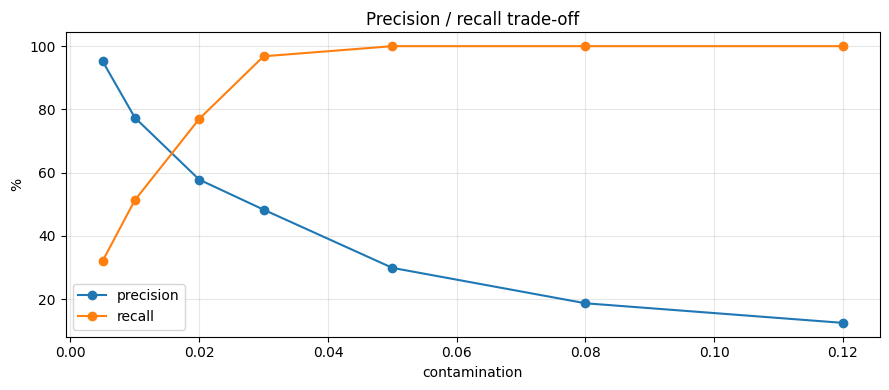

In [23]:
rows = []
for c in [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
    _, f = isolation_forest(X, contamination=c, seed=SEED)
    tp = len(f & truth)
    rows.append({"contamination": c, "flagged": len(f), "precision_pct": round(100 * tp / len(f), 1),
                 "recall_pct": round(100 * tp / len(truth), 1)})
sweep = pd.DataFrame(rows)
display(sweep)

plt.plot(sweep["contamination"], sweep["precision_pct"], marker="o", label="precision")
plt.plot(sweep["contamination"], sweep["recall_pct"], marker="o", label="recall")
plt.xlabel("contamination"); plt.ylabel("%"); plt.legend(); plt.title("Precision / recall trade-off")
plt.tight_layout(); plt.show()

## 9. Conclusions

* **Rules** found every injected defect (recall 100%) with no false alarms (precision 100%), and the warehouse passes
  re-validation with zero error-severity failures.
* **Dirty data has real cost:** revenue computed straight from the raw data was overstated by roughly 79%.
* **Statistics:** profiling exposed the extreme values; KS and chi-square tests (with effect sizes) showed that cleaning
  removed corrupt rows without reshaping the underlying numeric distributions.
* **ML:** Isolation Forest only worked well once given a domain-knowledge feature (price vs catalog), and it cannot see
  structural defects. Rules + ML together beat either alone.
* **Generic outlier tests (IQR, z-score) failed** because "normal" depends on the product category.

### Limitations (say these before an interviewer asks)
* The data is synthetic: the 100% numbers prove the validator works as designed, not that it would catch every real-world
  problem.
* `contamination` is an assumption; with real data, tune it or use a score threshold and review flagged rows.
* The injected errors (10× prices, 500-unit quantities) are extreme by design, which exaggerates the revenue impact.
* Everything runs in memory with Pandas; at millions of rows you would push checks into SQL or a framework like Great
  Expectations.

### Ideas to extend
1. Add a new check type (e.g. data freshness) with `@register`.
2. Try Local Outlier Factor or One-Class SVM and compare with Isolation Forest.
3. Run the pipeline on a **real** dataset (e.g. the Olist e-commerce dataset from Kaggle) and review the flagged rows by hand.
4. Wrap it in a Streamlit page or schedule it with GitHub Actions.